# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Malfino Muhammad Willianz | 5054251028 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import os

# Harus diset sebelum CUDA dipakai agar operasi cuBLAS deterministik
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

# Seed agar eksperimen reproducible
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Reproducibility pada GPU: paksa algoritma deterministik
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch : {torch.__version__}")
print(f"Device  : {device}")
if device == "cuda":
    print(f"GPU     : {torch.cuda.get_device_name(0)}")

PyTorch : 2.13.0+cu129
Device  : cuda
GPU     : NVIDIA GeForce RTX 5060 Ti


In [2]:
DATA_PATH = "data/Churn_Modelling.csv"
# Dataset asli tersedia di Kaggle. Jika file belum ada di lokal, unduh salinan CSV-nya.
DATA_URL = "https://raw.githubusercontent.com/sharmaroshan/Churn-Modelling-Dataset/master/Churn_Modelling.csv"

if not os.path.exists(DATA_PATH):
    os.makedirs(os.path.dirname(DATA_PATH), exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    print("Dataset diunduh dari:", DATA_URL)

df = pd.read_csv(DATA_PATH)
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
print("Jumlah baris dan kolom:", df.shape)
print()
df.info()
print()
print("Jumlah missing value per kolom:")
print(df.isna().sum().to_string())
print()
print("Statistik deskriptif fitur numerik:")
df.describe().T

Jumlah baris dan kolom: (10000, 14)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB

Jumlah missing value per kolom:
RowNumber          0
Cus

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


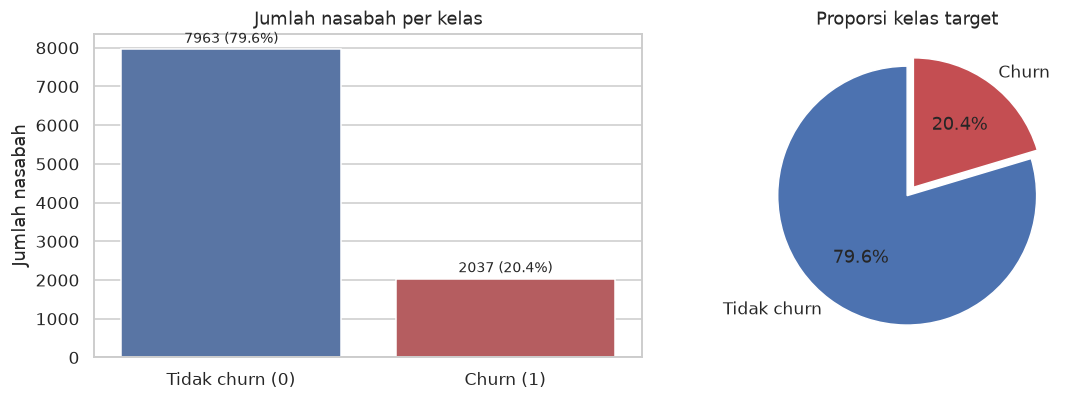

Rasio kelas mayoritas : minoritas = 3.91 : 1
Dataset tidak seimbang: kelas churn hanya ~20% dari total data.


In [4]:
# Distribusi kelas target (Exited)
counts = df["Exited"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.barplot(x=["Tidak churn (0)", "Churn (1)"], y=counts.values, ax=axes[0],
            palette=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 80, f"{v} ({v / len(df) * 100:.1f}%)", ha="center", va="bottom", fontsize=9)
axes[0].set_title("Jumlah nasabah per kelas")
axes[0].set_ylabel("Jumlah nasabah")

axes[1].pie(counts.values, labels=["Tidak churn", "Churn"], autopct="%1.1f%%",
            startangle=90, colors=["#4C72B0", "#C44E52"], explode=(0, 0.08))
axes[1].set_title("Proporsi kelas target")
plt.tight_layout()
plt.show()

print(f"Rasio kelas mayoritas : minoritas = {counts[0] / counts[1]:.2f} : 1")
print("Dataset tidak seimbang: kelas churn hanya ~20% dari total data.")

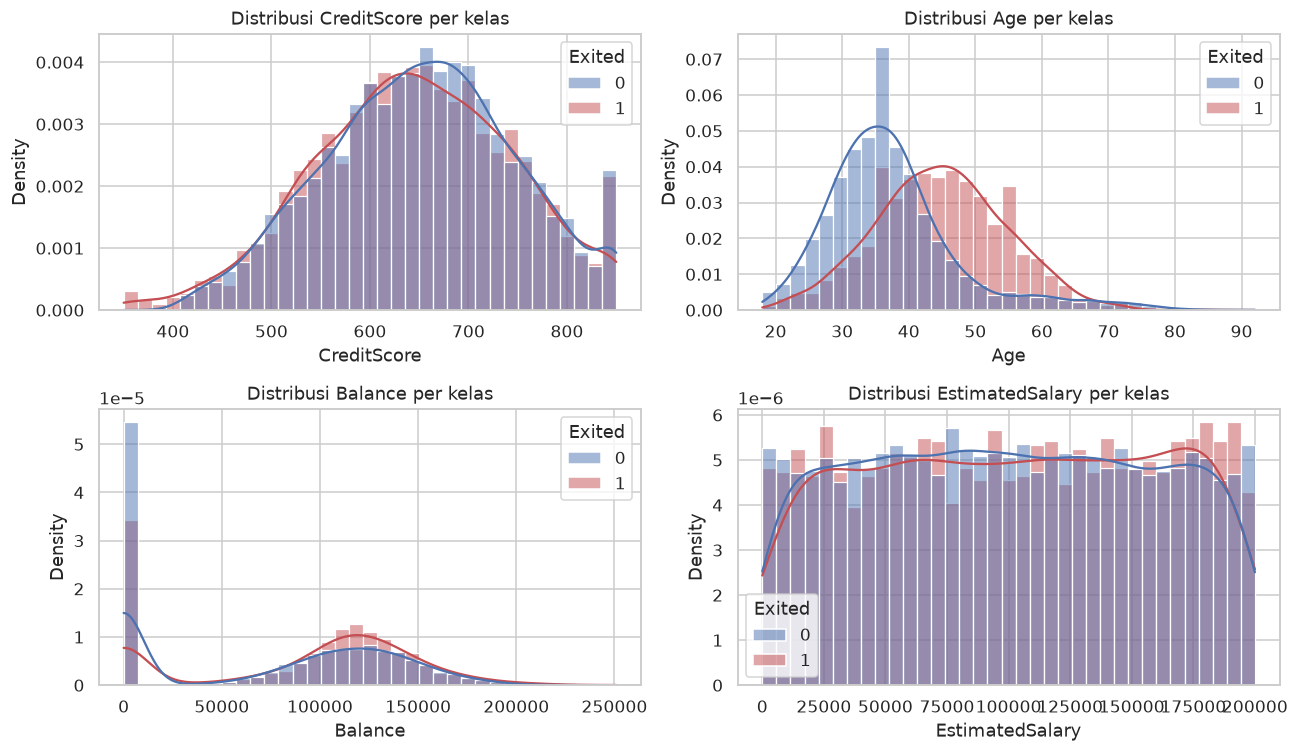

In [5]:
# Distribusi fitur numerik utama, dibedakan berdasarkan kelas Exited
num_cols_eda = ["CreditScore", "Age", "Balance", "EstimatedSalary"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.ravel(), num_cols_eda):
    sns.histplot(data=df, x=col, hue="Exited", bins=35, kde=True, ax=ax,
                 stat="density", common_norm=False, palette=["#4C72B0", "#C44E52"],
                 alpha=0.5)
    ax.set_title(f"Distribusi {col} per kelas")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

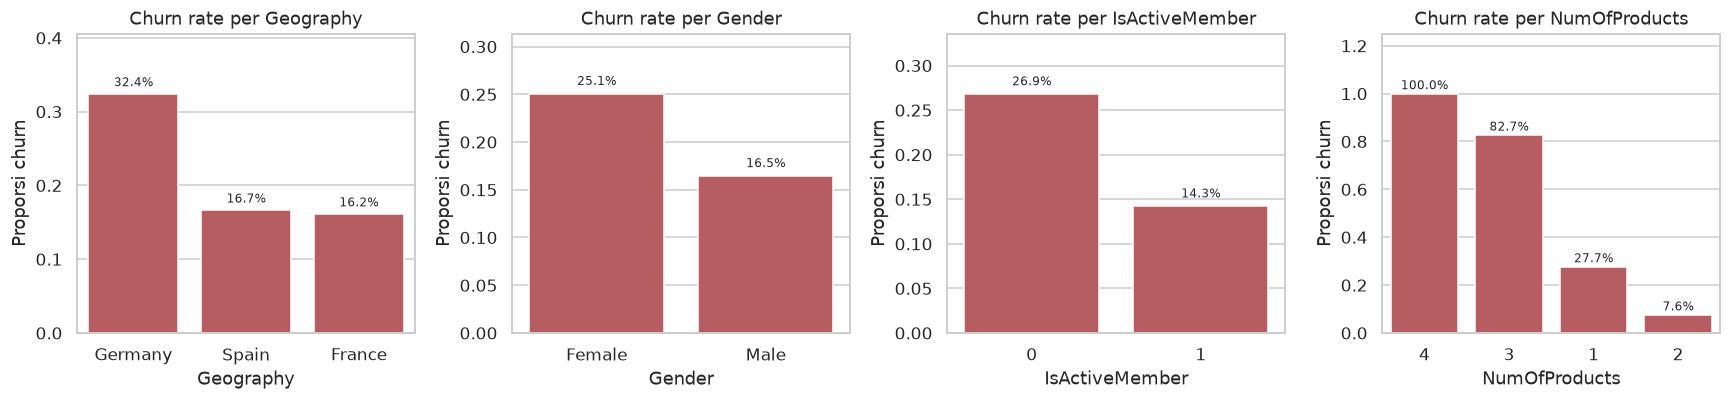

Churn rate per Geography:
           jumlah  churn_rate
Geography                    
France       5014      0.1615
Germany      2509      0.3244
Spain        2477      0.1667

Churn rate per Gender:
        jumlah  churn_rate
Gender                    
Female    4543      0.2507
Male      5457      0.1646

Churn rate per IsActiveMember:
                jumlah  churn_rate
IsActiveMember                    
0                 4849      0.2685
1                 5151      0.1427

Churn rate per NumOfProducts:
               jumlah  churn_rate
NumOfProducts                    
1                5084      0.2771
2                4590      0.0758
3                 266      0.8271
4                  60      1.0000



In [6]:
# Proporsi churn untuk setiap kategori pada fitur kategorikal
cat_cols_eda = ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, col in zip(axes, cat_cols_eda):
    prop = df.groupby(col)["Exited"].mean().sort_values(ascending=False)
    sns.barplot(x=prop.index.astype(str), y=prop.values, ax=ax, color="#C44E52")
    for i, v in enumerate(prop.values):
        ax.text(i, v + 0.006, f"{v * 100:.1f}%", ha="center", va="bottom", fontsize=8)
    ax.set_title(f"Churn rate per {col}")
    ax.set_ylabel("Proporsi churn")
    ax.set_ylim(0, prop.values.max() * 1.25)
plt.tight_layout()
plt.show()

for col in cat_cols_eda:
    print(f"Churn rate per {col}:")
    print(df.groupby(col)["Exited"].agg(jumlah="count", churn_rate="mean").round(4).to_string())
    print()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

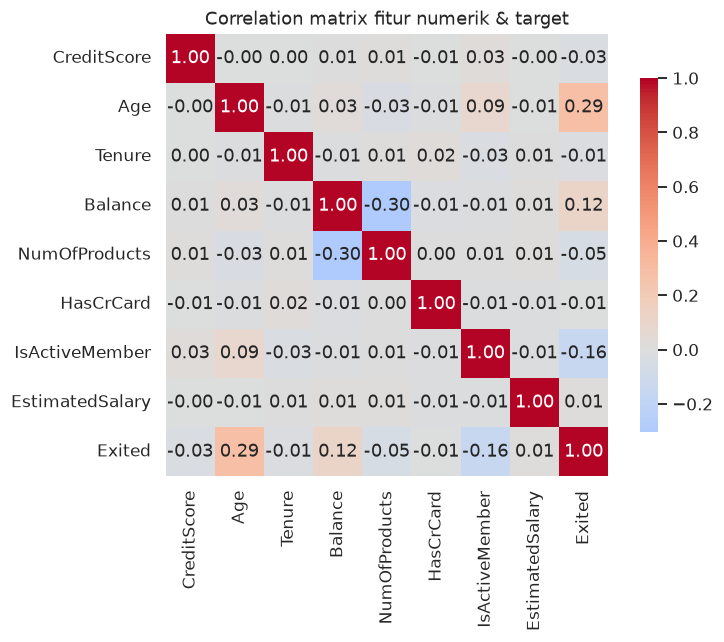

Korelasi linear tiap fitur numerik terhadap Exited:
Age                0.2853
IsActiveMember    -0.1561
Balance            0.1185
NumOfProducts     -0.0478
CreditScore       -0.0271
Tenure            -0.0140
EstimatedSalary    0.0121
HasCrCard         -0.0071
|r| maksimum = 0.285

Churn rate per NumOfProducts:
               jumlah  churn_rate
NumOfProducts                    
1                5084      0.2771
2                4590      0.0758
3                 266      0.8271
4                  60      1.0000

Nasabah dengan Balance = 0: 3617 (36.2% dari data)
balance_positif
False    0.1382
True     0.2408

Churn rate per Age group:
           jumlah  churn_rate
age_group                    
(17, 30]     1968      0.0752
(30, 40]     4451      0.1209
(40, 50]     2320      0.3397
(50, 60]      797      0.5621
(60, 100]     464      0.2478


In [7]:
# EDA tambahan: korelasi antar fitur numerik dan terhadap target
corr_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
             "HasCrCard", "IsActiveMember", "EstimatedSalary", "Exited"]

plt.figure(figsize=(7.5, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix fitur numerik & target")
plt.tight_layout()
plt.show()

korelasi_target = df[corr_cols].corr()["Exited"].drop("Exited").sort_values(key=abs, ascending=False)
print("Korelasi linear tiap fitur numerik terhadap Exited:")
print(korelasi_target.round(4).to_string())
print(f"|r| maksimum = {korelasi_target.abs().max():.3f}")

print("\nChurn rate per NumOfProducts:")
print(df.groupby("NumOfProducts")["Exited"]
        .agg(jumlah="count", churn_rate="mean").round(4).to_string())

print("\nNasabah dengan Balance = 0:", int((df["Balance"] == 0).sum()),
      f"({(df['Balance'] == 0).mean() * 100:.1f}% dari data)")
print(df.assign(balance_positif=df["Balance"] > 0)
        .groupby("balance_positif")["Exited"].mean().round(4).to_string())

print("\nChurn rate per Age group:")
print(df.assign(age_group=pd.cut(df["Age"], [17, 30, 40, 50, 60, 100]))
        .groupby("age_group", observed=True)["Exited"]
        .agg(jumlah="count", churn_rate="mean").round(4).to_string())

Dataset terdiri dari 10.000 baris dan 14 kolom. Tiga kolom (`RowNumber`, `CustomerId`, `Surname`) hanya berisi identitas dan tidak relevan untuk prediksi, sedangkan sisanya terdiri dari 8 fitur numerik dan 2 fitur kategorikal (`Geography`, `Gender`). Tidak ada missing value di seluruh kolom, sehingga tidak diperlukan imputasi.

Distribusi target tidak seimbang: 7.963 nasabah (79,63%) tidak churn dan hanya 2.037 nasabah (20,37%) yang churn, dengan rasio sekitar 3,91:1. Artinya model yang selalu memprediksi "tidak churn" sudah mendapat akurasi 79,63%, sehingga accuracy bukan metrik yang tepat untuk dataset ini. Precision, recall, dan F1-score pada kelas churn (1) jauh lebih relevan untuk dipantau.

Dari histogram per kelas, `Age` adalah fitur numerik yang paling jelas memisahkan kedua kelas. Churn rate naik dari 7,52% pada usia di bawah 30 tahun, 12,09% pada 30–40 tahun, 33,97% pada 40–50 tahun, dan mencapai 56,21% pada 50–60 tahun, lalu turun lagi menjadi 24,78% pada usia di atas 60 tahun. Pola ini tidak monoton, sehingga hubungan usia dengan churn berbentuk kurva dan sulit ditangkap model linear.

`Balance` juga menunjukkan pola yang tidak linear. Sebanyak 3.617 nasabah (36,2%) memiliki saldo 0 dengan churn rate 13,82%, sedangkan nasabah dengan saldo positif memiliki churn rate 24,08%. `NumOfProducts` justru menjadi sinyal terkuat: churn rate 27,71% untuk 1 produk, 7,58% untuk 2 produk, 82,71% untuk 3 produk, dan 100% untuk 4 produk (60 nasabah).

Pada fitur kategorikal, `Geography` menunjukkan churn rate 32,44% di Jerman, jauh di atas Prancis (16,15%) dan Spanyol (16,67%). Nasabah perempuan memiliki churn rate lebih tinggi (25,07%) dibanding laki-laki (16,46%), dan nasabah yang tidak aktif memiliki churn rate 26,85% dibanding 14,27% pada nasabah aktif.

Korelasi linear seluruh fitur numerik terhadap `Exited` lemah, dengan nilai |r| tertinggi hanya 0,285 pada `Age`, diikuti `IsActiveMember` (-0,156) dan `Balance` (0,118). Korelasi yang lemah ini tidak berarti fitur tidak berguna, karena hubungan fitur dengan target di dataset ini bersifat non-linear dan melibatkan interaksi antar fitur, sehingga ANN dengan hidden layer berpeluang mengungguli baseline linear.

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [8]:
# Drop kolom yang tidak relevan untuk prediksi:
# - RowNumber  : hanya nomor urut baris, tidak punya makna prediktif sama sekali.
# - CustomerId : identitas unik tiap nasabah, tidak bisa digeneralisasi ke nasabah baru.
# - Surname    : teks identitas dengan kardinalitas sangat tinggi (~2.800 nilai unik);
#                jika di-encode akan menambah ratusan dimensi noise tanpa hubungan kausal ke churn.
drop_cols = ["RowNumber", "CustomerId", "Surname"]
df_model = df.drop(columns=drop_cols)

print("Kolom yang di-drop:", drop_cols)
print("Jumlah kolom setelah drop:", df_model.shape[1])
print("Kolom tersisa:", list(df_model.columns))

Kolom yang di-drop: ['RowNumber', 'CustomerId', 'Surname']
Jumlah kolom setelah drop: 11
Kolom tersisa: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [9]:
# Pisahkan fitur (X) dan target (y)
X = df_model.drop(columns=["Exited"])
y = df_model["Exited"]

# 70% train, 15% validation, 15% test. stratify=y menjaga proporsi kelas di setiap set.
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

print(f"Train      : {X_train.shape[0]:5d} baris ({X_train.shape[0] / len(X) * 100:.0f}%)")
print(f"Validation : {X_val.shape[0]:5d} baris ({X_val.shape[0] / len(X) * 100:.0f}%)")
print(f"Test       : {X_test.shape[0]:5d} baris ({X_test.shape[0] / len(X) * 100:.0f}%)")
print()
print("Proporsi churn di tiap set:")
print(pd.DataFrame({"train": y_train.value_counts(normalize=True),
                    "validation": y_val.value_counts(normalize=True),
                    "test": y_test.value_counts(normalize=True)}).round(4).to_string())

Train      :  7000 baris (70%)
Validation :  1500 baris (15%)
Test       :  1500 baris (15%)

Proporsi churn di tiap set:
         train  validation    test
Exited                            
0       0.7963       0.796  0.7967
1       0.2037       0.204  0.2033


In [10]:
# Encoding kategorikal + scaling numerik dalam satu ColumnTransformer.
numeric_features = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
                    "HasCrCard", "IsActiveMember", "EstimatedSalary"]
nominal_features = ["Geography"]
binary_features = ["Gender"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_features),
        ("bin", OneHotEncoder(drop="if_binary", sparse_output=False), binary_features),
    ],
    verbose_feature_names_out=False,
)

# Fit HANYA pada train set, lalu transform ketiga set -> mencegah data leakage.
X_train_p = preprocessor.fit_transform(X_train)
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print("Jumlah fitur setelah preprocessing:", X_train_p.shape[1])
for i, name in enumerate(feature_names):
    print(f"  [{i}] {name}")

Jumlah fitur setelah preprocessing: 12
  [0] CreditScore
  [1] Age
  [2] Tenure
  [3] Balance
  [4] NumOfProducts
  [5] HasCrCard
  [6] IsActiveMember
  [7] EstimatedSalary
  [8] Geography_France
  [9] Geography_Germany
  [10] Geography_Spain
  [11] Gender_Male


In [11]:
# Konversi ke tensor float32; target dibentuk (N, 1) agar cocok dengan output model
def to_tensor(a):
    return torch.tensor(np.asarray(a), dtype=torch.float32)

X_train_t = to_tensor(X_train_p)
X_val_t = to_tensor(X_val_p)
X_test_t = to_tensor(X_test_p)

y_train_t = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=BATCH_SIZE, shuffle=False)

print("Bentuk X_train:", tuple(X_train_t.shape), "| y_train:", tuple(y_train_t.shape))
print("Bentuk X_val  :", tuple(X_val_t.shape), "| y_val  :", tuple(y_val_t.shape))
print("Bentuk X_test :", tuple(X_test_t.shape), "| y_test :", tuple(y_test_t.shape))
print("Jumlah batch train per epoch:", len(train_loader))

Bentuk X_train: (7000, 12) | y_train: (7000, 1)
Bentuk X_val  : (1500, 12) | y_val  : (1500, 1)
Bentuk X_test : (1500, 12) | y_test : (1500, 1)
Jumlah batch train per epoch: 110


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [12]:
log_reg = LogisticRegression(max_iter=1000, random_state=SEED)
log_reg.fit(X_train_p, y_train)

y_prob_lr = log_reg.predict_proba(X_test_p)[:, 1]
y_pred_lr = (y_prob_lr >= 0.5).astype(int)

print("Logistic Regression (baseline) - hasil pada test set")
print(f"  Accuracy : {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"  Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"  Recall   : {recall_score(y_test, y_pred_lr):.4f}")
print(f"  F1-Score : {f1_score(y_test, y_pred_lr):.4f}")
print(f"  ROC-AUC  : {roc_auc_score(y_test, y_prob_lr):.4f}")

Logistic Regression (baseline) - hasil pada test set
  Accuracy : 0.8153
  Precision: 0.6458
  Recall   : 0.2033
  F1-Score : 0.3092
  ROC-AUC  : 0.7912


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [13]:
class SimpleANN(nn.Module):
    # ANN 1 hidden layer: Input -> Linear(16) -> ReLU -> Linear(1)
    def __init__(self, n_features, hidden=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),   # output logit, tanpa Sigmoid
        )

    def forward(self, x):
        return self.net(x)


n_features = X_train_t.shape[1]
model_simple = SimpleANN(n_features).to(device)

print(model_simple)
print("Jumlah parameter:", sum(p.numel() for p in model_simple.parameters()))

SimpleANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 225


In [14]:
def train_model(model, train_loader, val_loader, criterion, optimizer,
                epochs, device=device, verbose=True):
    # Training loop generik untuk klasifikasi biner (output logit)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(1, epochs + 1):
        # ---- training ----
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * xb.size(0)
            preds = (torch.sigmoid(logits) >= 0.5).float()
            correct += (preds == yb).sum().item()
            total += yb.size(0)
        history["train_loss"].append(running_loss / total)
        history["train_acc"].append(correct / total)

        # ---- validation ----
        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                preds = (torch.sigmoid(logits) >= 0.5).float()
                correct += (preds == yb).sum().item()
                total += yb.size(0)
        history["val_loss"].append(running_loss / total)
        history["val_acc"].append(correct / total)

        if verbose and (epoch == 1 or epoch % 10 == 0):
            print(f"Epoch {epoch:3d}/{epochs} | "
                  f"train_loss {history['train_loss'][-1]:.4f} acc {history['train_acc'][-1]:.4f} | "
                  f"val_loss {history['val_loss'][-1]:.4f} acc {history['val_acc'][-1]:.4f}")
    return history


def plot_learning_curve(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], label="Train", marker="o", ms=2)
    axes[0].plot(epochs, history["val_loss"], label="Validation", marker="o", ms=2)
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE Loss"); axes[0].legend()
    axes[1].plot(epochs, history["train_acc"], label="Train", marker="o", ms=2)
    axes[1].plot(epochs, history["val_acc"], label="Validation", marker="o", ms=2)
    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
    plt.tight_layout()
    plt.show()


def predict_proba_nn(model, loader):
    # Kembalikan probabilitas kelas 1 (setelah Sigmoid) sebagai numpy array
    model.eval()
    probs = []
    with torch.no_grad():
        for xb, _ in loader:
            probs.append(torch.sigmoid(model(xb.to(device))).cpu())
    return torch.cat(probs).numpy().ravel()


# Hyperparameter
EPOCHS = 100
LR = 1e-3

criterion_simple = nn.BCEWithLogitsLoss()
optimizer_simple = torch.optim.Adam(model_simple.parameters(), lr=LR)

history_simple = train_model(model_simple, train_loader, val_loader,
                             criterion_simple, optimizer_simple, EPOCHS)

Epoch   1/100 | train_loss 0.5654 acc 0.7836 | val_loss 0.5029 acc 0.7960


Epoch  10/100 | train_loss 0.3681 acc 0.8497 | val_loss 0.3503 acc 0.8547


Epoch  20/100 | train_loss 0.3476 acc 0.8573 | val_loss 0.3289 acc 0.8627


Epoch  30/100 | train_loss 0.3429 acc 0.8584 | val_loss 0.3246 acc 0.8640


Epoch  40/100 | train_loss 0.3412 acc 0.8573 | val_loss 0.3235 acc 0.8593


Epoch  50/100 | train_loss 0.3398 acc 0.8579 | val_loss 0.3227 acc 0.8620


Epoch  60/100 | train_loss 0.3384 acc 0.8576 | val_loss 0.3214 acc 0.8660


Epoch  70/100 | train_loss 0.3383 acc 0.8580 | val_loss 0.3225 acc 0.8633


Epoch  80/100 | train_loss 0.3370 acc 0.8590 | val_loss 0.3240 acc 0.8640


Epoch  90/100 | train_loss 0.3364 acc 0.8593 | val_loss 0.3217 acc 0.8647


Epoch 100/100 | train_loss 0.3358 acc 0.8593 | val_loss 0.3221 acc 0.8667


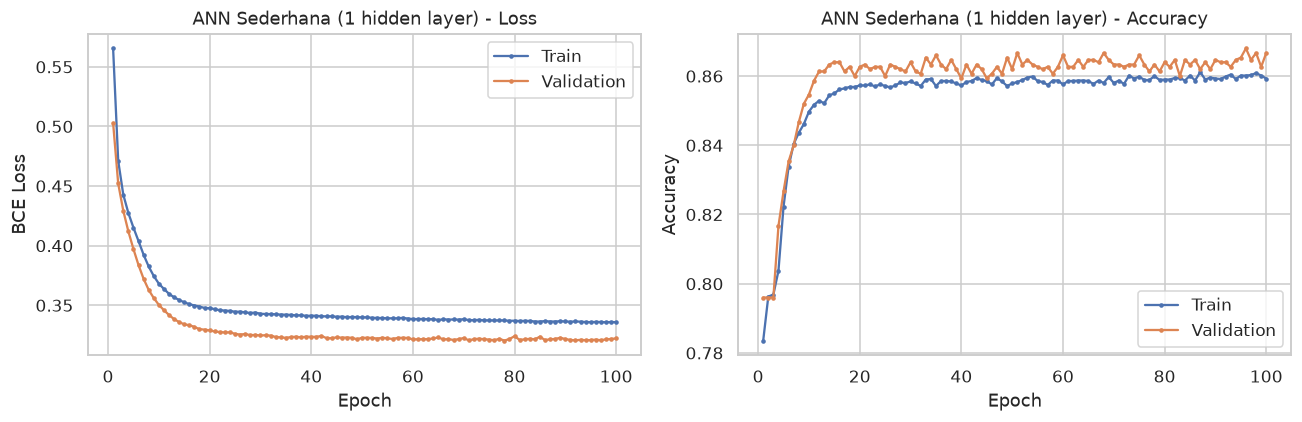

In [15]:
plot_learning_curve(history_simple, "ANN Sederhana (1 hidden layer)")

In [16]:
y_prob_simple = predict_proba_nn(model_simple, test_loader)
y_pred_simple = (y_prob_simple >= 0.5).astype(int)

print("Contoh probabilitas churn (5 data pertama):", np.round(y_prob_simple[:5], 4))
print("Bentuk array probabilitas:", y_prob_simple.shape)
print("Bentuk array label       :", y_pred_simple.shape)
print("Jumlah prediksi churn    :", int(y_pred_simple.sum()))

Contoh probabilitas churn (5 data pertama): [0.2327 0.0149 0.0718 0.0447 0.2363]
Bentuk array probabilitas: (1500,)
Bentuk array label       : (1500,)
Jumlah prediksi churn    : 209


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [17]:
class DeepANN(nn.Module):
    # ANN 3 hidden layer dengan Dropout di antara hidden layer
    def __init__(self, n_features, p_dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 64),
            nn.ReLU(),
            nn.Dropout(p_dropout),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(p_dropout),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(p_dropout),
            nn.Linear(16, 1),   # output logit
        )

    def forward(self, x):
        return self.net(x)


model_deep = DeepANN(n_features, p_dropout=0.3).to(device)
print(model_deep)
print("Jumlah parameter:", sum(p.numel() for p in model_deep.parameters()))

DeepANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 3457


In [18]:
criterion_deep = nn.BCEWithLogitsLoss()
optimizer_deep = torch.optim.Adam(model_deep.parameters(), lr=LR)

history_deep = train_model(model_deep, train_loader, val_loader,
                           criterion_deep, optimizer_deep, EPOCHS)

Epoch   1/100 | train_loss 0.5255 acc 0.7960 | val_loss 0.4389 acc 0.7960


Epoch  10/100 | train_loss 0.3660 acc 0.8483 | val_loss 0.3304 acc 0.8660


Epoch  20/100 | train_loss 0.3660 acc 0.8536 | val_loss 0.3283 acc 0.8680


Epoch  30/100 | train_loss 0.3534 acc 0.8596 | val_loss 0.3239 acc 0.8700


Epoch  40/100 | train_loss 0.3444 acc 0.8599 | val_loss 0.3267 acc 0.8660


Epoch  50/100 | train_loss 0.3377 acc 0.8641 | val_loss 0.3236 acc 0.8680


Epoch  60/100 | train_loss 0.3436 acc 0.8617 | val_loss 0.3248 acc 0.8693


Epoch  70/100 | train_loss 0.3348 acc 0.8663 | val_loss 0.3243 acc 0.8647


Epoch  80/100 | train_loss 0.3386 acc 0.8651 | val_loss 0.3257 acc 0.8640


Epoch  90/100 | train_loss 0.3279 acc 0.8681 | val_loss 0.3267 acc 0.8640


Epoch 100/100 | train_loss 0.3235 acc 0.8664 | val_loss 0.3291 acc 0.8620


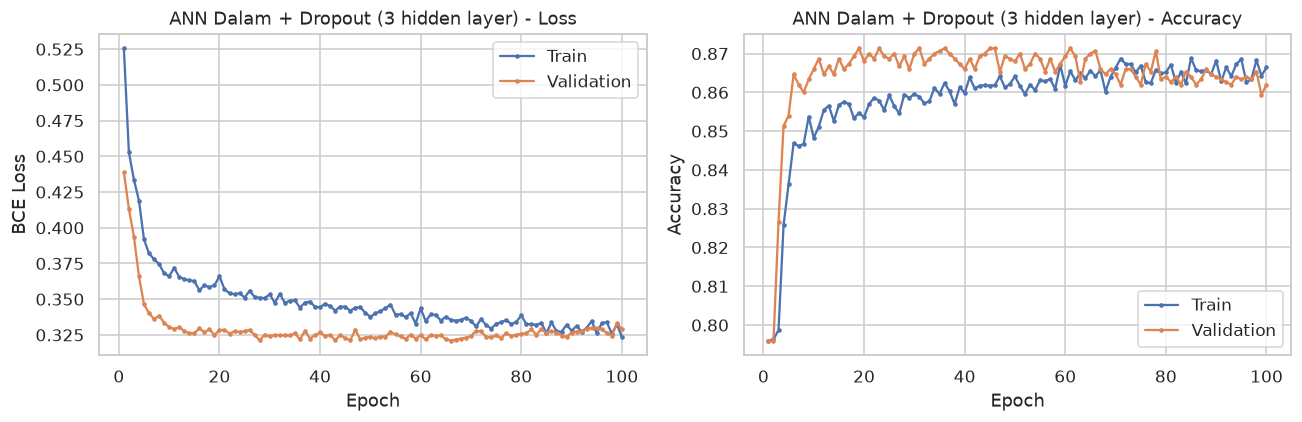

In [19]:
plot_learning_curve(history_deep, "ANN Dalam + Dropout (3 hidden layer)")

**Perbandingan dengan 3.2:** bentuk kurva hampir sama, keduanya konvergen di sekitar epoch 20–30. Model ini lebih rapi pada data validasi dengan gap train-validation hanya +0,44 poin. Loss validasi mencapai minimum 0,3236 pada epoch 50 lalu naik ke 0,3291 pada epoch 100, sementara loss training terus turun, yang menandakan overfitting ringan sudah mulai terjadi dan berhasil ditahan oleh Dropout. Akurasi validasi terbaik 0,8700 (epoch 30) sedikit lebih tinggi dari model 3.2 (0,8667), tetapi pada test set F1-nya lebih rendah (0,5885 vs 0,6148). Dengan demikian penambahan layer dan Dropout tidak memberikan perbaikan nyata pada dataset ini.

In [20]:
y_prob_deep = predict_proba_nn(model_deep, test_loader)
y_pred_deep = (y_prob_deep >= 0.5).astype(int)

print("Contoh probabilitas churn (5 data pertama):", np.round(y_prob_deep[:5], 4))
print("Jumlah prediksi churn:", int(y_pred_deep.sum()))

Contoh probabilitas churn (5 data pertama): [0.1545 0.0288 0.0153 0.076  0.1866]
Jumlah prediksi churn: 181


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [21]:
# Arsitektur terbaik (ANN dalam + Dropout) dilatih ulang dari awal dengan class weight.
n_pos = int(y_train.sum())
n_neg = int(len(y_train) - n_pos)
pos_weight = n_neg / n_pos
print(f"Train set -> kelas 0: {n_neg}, kelas 1: {n_pos}")
print(f"pos_weight = {n_neg} / {n_pos} = {pos_weight:.4f}")

model_weighted = DeepANN(n_features, p_dropout=0.3).to(device)
criterion_weighted = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor([pos_weight], dtype=torch.float32, device=device))
optimizer_weighted = torch.optim.Adam(model_weighted.parameters(), lr=LR)

history_weighted = train_model(model_weighted, train_loader, val_loader,
                               criterion_weighted, optimizer_weighted, EPOCHS)

Train set -> kelas 0: 5574, kelas 1: 1426
pos_weight = 5574 / 1426 = 3.9088


Epoch   1/100 | train_loss 1.0841 acc 0.4294 | val_loss 0.9927 acc 0.6933


Epoch  10/100 | train_loss 0.8018 acc 0.7743 | val_loss 0.7167 acc 0.7847


Epoch  20/100 | train_loss 0.7723 acc 0.7763 | val_loss 0.7021 acc 0.8080


Epoch  30/100 | train_loss 0.7606 acc 0.7780 | val_loss 0.6997 acc 0.8080


Epoch  40/100 | train_loss 0.7439 acc 0.7807 | val_loss 0.6829 acc 0.7960


... (2 outputs left out)

Epoch  70/100 | train_loss 0.7140 acc 0.7903 | val_loss 0.6922 acc 0.7987


Epoch  80/100 | train_loss 0.7289 acc 0.7833 | val_loss 0.6981 acc 0.7933


Epoch  90/100 | train_loss 0.7119 acc 0.7907 | val_loss 0.6937 acc 0.7873


Epoch 100/100 | train_loss 0.7087 acc 0.7886 | val_loss 0.6962 acc 0.7873


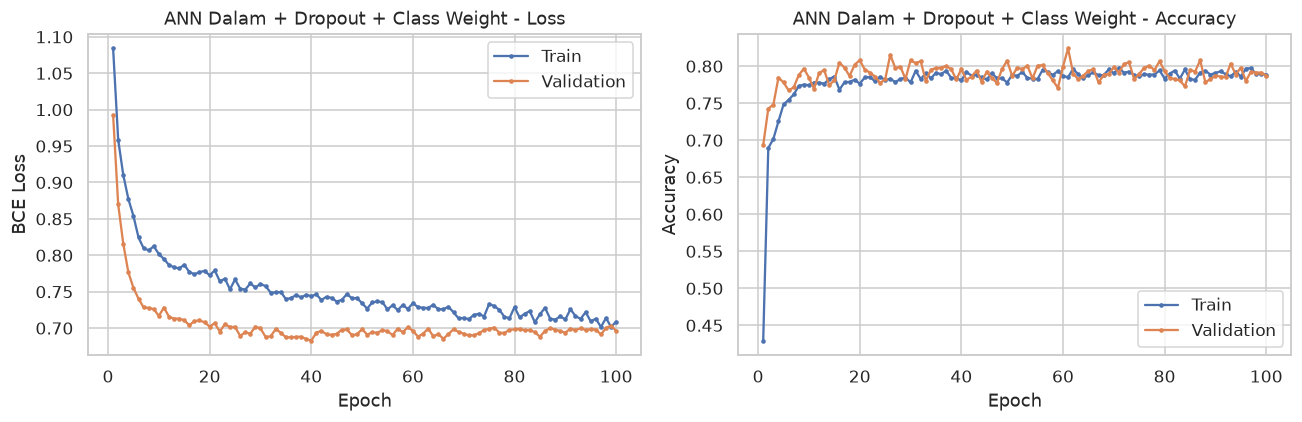

In [22]:
plot_learning_curve(history_weighted, "ANN Dalam + Dropout + Class Weight")

**Perbandingan dengan 3.3:** dengan class weight, kurva loss berada pada skala yang berbeda (0,70 vs 0,33) karena suku loss untuk kelas positif dikalikan `pos_weight` = 3,91. Nilai loss yang lebih besar bukan berarti model lebih buruk, karena skala loss kedua model tidak lagi sebanding. Yang berubah secara substantif adalah perilaku prediksi: jumlah prediksi churn naik dari 181 menjadi 505 dari 1.500 data test, recall naik dari 0,4689 ke 0,7836, dan precision turun dari 0,7901 ke 0,4733. Gap train-validation tetap kecil (+0,12 poin), sehingga pembobotan kelas tidak memunculkan overfitting baru.

In [23]:
y_prob_weighted = predict_proba_nn(model_weighted, test_loader)
y_pred_weighted = (y_prob_weighted >= 0.5).astype(int)

print("Contoh probabilitas churn (5 data pertama):", np.round(y_prob_weighted[:5], 4))
print("Jumlah prediksi churn:", int(y_pred_weighted.sum()))

Contoh probabilitas churn (5 data pertama): [0.3487 0.0852 0.0836 0.2166 0.5107]
Jumlah prediksi churn: 505


# 4. Evaluasi Model

In [24]:
results = {
    "Logistic Regression": {"y_true": y_test.values, "y_pred": y_pred_lr, "y_prob": y_prob_lr},
    "ANN Sederhana": {"y_true": y_test.values, "y_pred": y_pred_simple, "y_prob": y_prob_simple},
    "ANN Dalam + Dropout": {"y_true": y_test.values, "y_pred": y_pred_deep, "y_prob": y_prob_deep},
    "ANN + Class Weight": {"y_true": y_test.values, "y_pred": y_pred_weighted, "y_prob": y_prob_weighted},
}

rows = []
for name, r in results.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(r["y_true"], r["y_pred"]),
        "Precision": precision_score(r["y_true"], r["y_pred"]),
        "Recall": recall_score(r["y_true"], r["y_pred"]),
        "F1-Score": f1_score(r["y_true"], r["y_pred"]),
        "ROC-AUC": roc_auc_score(r["y_true"], r["y_prob"]),
    })

metrics_df = pd.DataFrame(rows).set_index("Model").round(4)
print(metrics_df.to_string())
print()
print("Catatan: Precision/Recall/F1 dihitung untuk kelas positif = churn (Exited = 1).")

                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                              
Logistic Regression    0.8153     0.6458  0.2033    0.3092   0.7912
ANN Sederhana          0.8680     0.7560  0.5180    0.6148   0.8687
ANN Dalam + Dropout    0.8667     0.7901  0.4689    0.5885   0.8602
ANN + Class Weight     0.7787     0.4733  0.7836    0.5901   0.8597

Catatan: Precision/Recall/F1 dihitung untuk kelas positif = churn (Exited = 1).


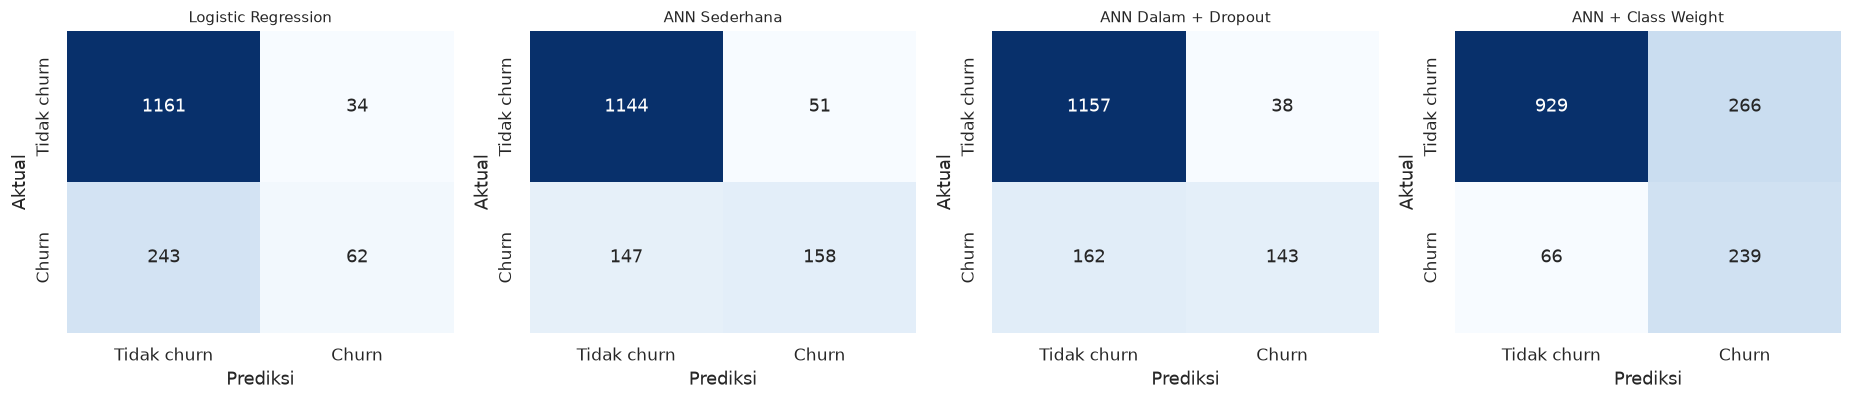

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(r["y_true"], r["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Tidak churn", "Churn"], yticklabels=["Tidak churn", "Churn"])
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
plt.tight_layout()
plt.show()

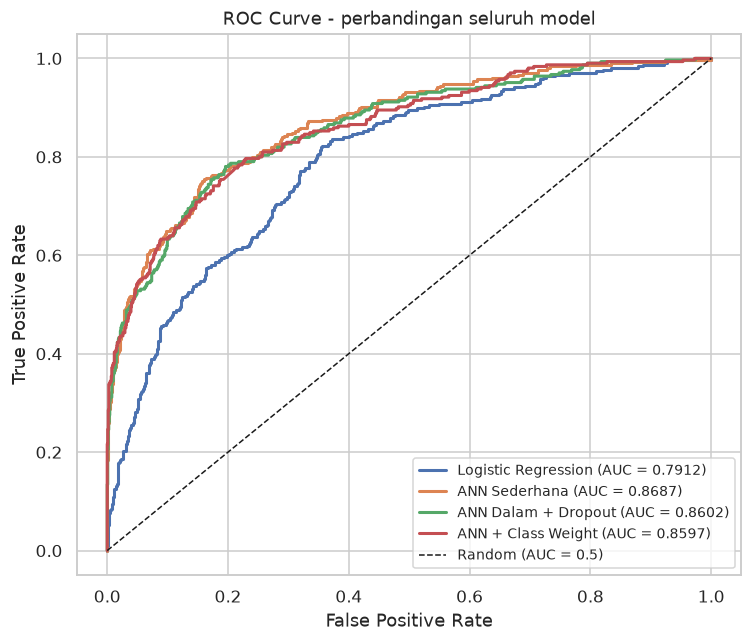

In [26]:
plt.figure(figsize=(7, 6))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(r["y_true"], r["y_prob"])
    plt.plot(fpr, tpr, lw=2,
             label=f"{name} (AUC = {roc_auc_score(r['y_true'], r['y_prob']):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - perbandingan seluruh model")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

In [27]:
print("Ringkasan gap train vs validation pada epoch terakhir:")
print(f"{'Model':22s} {'train_acc':>10s} {'val_acc':>9s} {'gap_acc':>9s} {'train_loss':>11s} {'val_loss':>9s}")
for name, h in [("ANN Sederhana", history_simple),
                ("ANN Dalam + Dropout", history_deep),
                ("ANN + Class Weight", history_weighted)]:
    gap = h["train_acc"][-1] - h["val_acc"][-1]
    print(f"{name:22s} {h['train_acc'][-1]:10.4f} {h['val_acc'][-1]:9.4f} {gap:+9.4f} "
          f"{h['train_loss'][-1]:11.4f} {h['val_loss'][-1]:9.4f}")

print()
print("Jumlah parameter tiap model:")
print(f"  ANN Sederhana        : {sum(p.numel() for p in model_simple.parameters()):,}")
print(f"  ANN Dalam + Dropout  : {sum(p.numel() for p in model_deep.parameters()):,}")
print(f"  ANN + Class Weight   : {sum(p.numel() for p in model_weighted.parameters()):,}")
print(f"  Logistic Regression  : {log_reg.coef_.size + log_reg.intercept_.size:,}")

Ringkasan gap train vs validation pada epoch terakhir:
Model                   train_acc   val_acc   gap_acc  train_loss  val_loss
ANN Sederhana              0.8593    0.8667   -0.0074      0.3358    0.3221
ANN Dalam + Dropout        0.8664    0.8620   +0.0044      0.3235    0.3291
ANN + Class Weight         0.7886    0.7873   +0.0012      0.7087    0.6962

Jumlah parameter tiap model:
  ANN Sederhana        : 225
  ANN Dalam + Dropout  : 3,457
  ANN + Class Weight   : 3,457
  Logistic Regression  : 13


# 5. Analisis

### 5.1 Ringkasan hasil eksperimen

| Model | Parameter | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---|---|---|---|---|---|---|
| Logistic Regression (baseline) | 13 | 0.8153 | 0.6458 | 0.2033 | 0.3092 | 0.7912 |
| ANN Sederhana (1 hidden layer) | 225 | **0.8680** | 0.7560 | 0.5180 | **0.6148** | **0.8687** |
| ANN Dalam + Dropout (3 hidden layer) | 3.457 | 0.8667 | **0.7901** | 0.4689 | 0.5885 | 0.8602 |
| ANN Dalam + Dropout + Class Weight | 3.457 | 0.7787 | 0.4733 | **0.7836** | 0.5901 | 0.8597 |

Seluruh metrik di atas dihitung pada test set (1.500 data, 305 di antaranya churn) yang tidak dipakai saat training maupun pemilihan model. Karena kelas churn hanya 20,37% dari data, accuracy bukan metrik utama di sini. Model yang selalu menebak "tidak churn" sudah mendapat akurasi 79,67%, sehingga metrik yang menentukan kualitas model adalah recall dan F1-score kelas churn.

**1. Logistic Regression mendapat akurasi tinggi, tetapi hampir tidak mendeteksi churn.**

Akurasi 0,8153 hanya 0,5 poin di atas proporsi kelas mayoritas, dengan recall 0,2033. Dari 305 nasabah yang benar-benar churn, model hanya menangkap sekitar 62 nasabah dan melewatkan sekitar 243 nasabah (false negative). Precision 0,6458 berarti ketika model memprediksi churn, sekitar 2 dari 3 prediksi benar.

Pola ini adalah gejala klasik class imbalance, karena kesalahan pada kelas mayoritas "dihukum" 3,91 kali lebih sering sehingga model linear lebih memilih condong ke kelas 0. Nilai ROC-AUC 0,7912 menunjukkan bahwa ranking probabilitas model sebenarnya cukup baik, sehingga masalahnya ada pada ambang keputusan 0,5 yang tidak sesuai untuk data timpang, bukan pada kemampuan model memisahkan kelas.

**2. ANN sederhana memberikan peningkatan terbesar dengan biaya parameter paling kecil.**

ANN dengan satu hidden layer (16 neuron, 225 parameter, hanya 17 kali parameter LR) menaikkan seluruh metrik sekaligus: accuracy 0,8153 ke 0,8680, recall 0,2033 ke 0,5180 (churn yang tertangkap naik dari sekitar 62 menjadi sekitar 158 dari 305), F1-score 0,3092 ke 0,6148 atau dua kali lipat, dan ROC-AUC 0,7912 ke 0,8687.

Peningkatan ini masuk akal dari hasil EDA, karena hubungan fitur dengan target di dataset ini tidak linear dan melibatkan interaksi antar fitur. Contohnya `NumOfProducts` (churn rate 27,71% untuk 1 produk, 7,58% untuk 2 produk, tetapi 82,71% untuk 3 produk dan 100% untuk 4 produk), kombinasi `Balance` = 0 vs `Balance` > 0 (13,82% vs 24,08%), serta efek usia yang memuncak di 50–60 tahun (56,21%) lalu turun lagi di atas 60 tahun (24,78%). Hubungan berbentuk kurva dan interaksi semacam ini tidak bisa direpresentasikan model linear, tetapi dapat dipelajari ReLU dan hidden layer. Korelasi linear maksimum fitur numerik terhadap target hanya 0,285 pada `Age`, sehingga baseline linear memang kehilangan banyak sinyal non-linear.

**3. Menambah layer dan Dropout tidak memperbaiki F1, tetapi menaikkan precision.**

Model 3 hidden layer (64-32-16) dengan Dropout 0,3 memiliki 3.457 parameter, 15 kali model 3.2, namun hasilnya hampir identik dan sedikit lebih rendah pada F1 (0,5885 vs 0,6148). Model yang lebih dalam menjadi lebih konservatif: prediksi churn turun dari 209 ke 181, precision naik 3,4 poin, tetapi recall turun 4,9 poin sehingga F1 sedikit menurun.

Dengan hanya 7.000 baris training dan 12 fitur, sinyal yang bisa dipelajari sudah terserap oleh 225 parameter, sehingga penambahan 3.232 parameter hanya menambah variansi tanpa informasi baru. Hal ini menunjukkan over-parameterization tanpa manfaat, bukan overfitting.

**4. Class weight menggeser titik operasi, bukan menaikkan kemampuan model.**

Dengan `pos_weight` = 5574 / 1426 = 3,9088, setiap kesalahan pada kelas churn dihukum sekitar 3,9 kali lebih berat. Recall naik dari 0,4689 ke 0,7836 (sekitar 239 dari 305 churn tertangkap), tetapi precision turun dari 0,7901 ke 0,4733 karena 266 nasabah yang sebenarnya tidak churn ikut ditandai, dan accuracy turun menjadi 0,7787.

Yang penting, F1 hampir tidak berubah (0,5885 ke 0,5901) dan ROC-AUC praktis identik (0,8602 ke 0,8597). Ini menunjukkan bahwa class weight tidak menambah kemampuan diskriminasi model, melainkan hanya menggeser threshold efektif ke arah recall tinggi, mirip menurunkan ambang dari 0,5 menjadi sekitar 0,25. Karena itu class weight lebih tepat dipandang sebagai pilihan kebijakan biaya, dipakai bila melewatkan nasabah yang akan churn jauh lebih mahal daripada menghubungi nasabah yang tidak churn.

**5. Learning curve menunjukkan underfitting ringan, bukan overfitting.**

| Model | train_acc | val_acc | gap | train_loss | val_loss |
|---|---|---|---|---|---|
| ANN Sederhana | 0.8593 | 0.8667 | -0.0074 | 0.3358 | 0.3221 |
| ANN Dalam + Dropout | 0.8664 | 0.8620 | +0.0044 | 0.3235 | 0.3291 |
| ANN + Class Weight | 0.7886 | 0.7873 | +0.0012 | 0.7087 | 0.6962 |

Selisih train-validation accuracy ketiga model di bawah 1 poin. Pada ANN sederhana akurasi validasi bahkan sedikit lebih tinggi dari training (-0,74 poin), yang wajar karena akurasi training dihitung selama training berlangsung dan karena noise sampling pada 7.000 data. Ini indikasi underfitting ringan, bukan overfitting.

Ketiga kurva konvergen cepat di sekitar epoch 20–30 lalu mendatar, dan setelah itu penambahan epoch hanya memperbaiki loss training sangat sedikit (0,3660 pada epoch 10 ke 0,3235 pada epoch 100 pada model 3.3) sementara loss validasi tidak lagi turun. Model 3.3 menunjukkan awal overfitting paling jelas meski sangat ringan: loss validasi minimum 0,3236 pada epoch 50 lalu naik ke 0,3291 pada epoch 100, sementara loss training terus turun, dan akurasi validasi terbaiknya 0,8700 (epoch 30) lebih tinggi dari nilai akhir 0,8620. Jadi Dropout berhasil menahan overfitting dengan gap tetap sekitar 0,4 poin, tetapi tidak mampu membuat model dalam mengungguli model dangkal, yang menegaskan bahwa masalahnya adalah keterbatasan sinyal dan data, bukan kapasitas.

**6. Keterbatasan eksperimen.**

Hanya satu kali run per konfigurasi (single seed), sehingga perbedaan F1 antara 3.2 dan 3.3 (0,026) berada dalam rentang variasi antar-seed dan keduanya sebaiknya dianggap setara. Threshold tetap 0,5 untuk semua model, padahal untuk data timpang threshold sebaiknya dioptimasi pada validation set. Tidak ada hyperparameter tuning sistematis maupun validasi silang, dan fitur belum direkayasa sehingga beberapa sinyal dari EDA (flag `Balance` = 0, binning usia, interaksi `NumOfProducts` dengan `IsActiveMember`) belum diberikan secara eksplisit ke model.

# 6. Kesimpulan dan Saran

**Kesimpulan:**

1. ANN mengungguli Logistic Regression secara meyakinkan pada tugas ini. Baseline linear hanya mencapai F1 0,3092 dan recall 0,2033, sehingga melewatkan sekitar 243 dari 305 nasabah churn, sedangkan ANN sederhana dengan 225 parameter mencapai F1 0,6148 dan recall 0,5180. Selisih ini berasal dari kemampuan ANN menangkap hubungan non-linear dan interaksi antar fitur (`NumOfProducts`, `Balance`, `Age`) yang tidak dapat direpresentasikan model linear.
2. Model terbaik untuk metrik gabungan adalah ANN sederhana dengan 1 hidden layer dan 16 neuron. Model ini memberi F1 tertinggi (0,6148), ROC-AUC tertinggi (0,8687), dan hanya 225 parameter. Menambah kedalaman menjadi 3 hidden layer dengan Dropout (3.457 parameter) tidak meningkatkan F1 (0,5885): precision memang naik ke 0,7901, tetapi recall turun ke 0,4689. Pada dataset tabular kecil (7.000 baris, 12 fitur) kapasitas tambahan tidak terpakai.
3. Class weight adalah alat untuk menggeser trade-off, bukan untuk menaikkan performa. Dengan `pos_weight` = 3,91, recall melonjak ke 0,7836 (sekitar 239 dari 305 churn tertangkap) tetapi precision jatuh ke 0,4733 dan akurasi ke 0,7787, sementara F1 (0,5901) dan ROC-AUC (0,8597) hampir tidak berubah. Artinya kemampuan diskriminasi model tetap sama, yang berubah hanya titik operasinya.
4. Tidak terjadi overfitting berarti pada eksperimen ini. Gap train-validation accuracy di bawah 1 poin pada semua model dan kurva konvergen sekitar epoch 20–30. Model terdalam justru menunjukkan tanda keterbatasan sinyal, dengan loss validasi minimum di epoch 50 yang kembali naik, sementara loss training terus turun. Dropout berperan menahan selisih tersebut tetap kecil.
5. Pemilihan model akhir sebaiknya mengikuti biaya bisnis, bukan hanya F1. Jika tujuan utamanya memaksimalkan nasabah churn yang berhasil dihubungi dan biaya kontak murah, gunakan ANN dengan class weight (recall 0,7836). Jika tim retensi punya kapasitas terbatas dan setiap kontak mahal, gunakan ANN sederhana atau ANN dengan Dropout yang precision-nya 0,76 sampai 0,79.

**Saran untuk eksperimen selanjutnya:**

1. **Optimasi threshold pada validation set:** memakai kurva precision-recall alih-alih threshold 0,5. Dengan ROC-AUC 0,86, menggeser threshold memberi kontrol langsung atas trade-off precision-recall tanpa perlu melatih ulang model, sehingga lebih murah dan lebih mudah dikalibrasi daripada class weight.
2. **Feature engineering dari temuan EDA:** flag `Balance` = 0, transformasi `Age` karena efeknya tidak monoton, interaksi `NumOfProducts` dengan `IsActiveMember` dan `Geography`, serta rasio `Balance` terhadap `EstimatedSalary`.
3. **Hyperparameter tuning yang terukur:** grid atau random search atas jumlah neuron, dropout rate, learning rate, weight decay, dan batch size, disertai early stopping berbasis validation loss. Pada eksperimen ini early stopping di sekitar epoch 30–50 akan menghemat waktu sekaligus menghindari kenaikan loss validasi.
4. **Evaluasi dengan validasi silang:** stratified k-fold dan beberapa seed, lalu laporkan rata-rata dengan standar deviasi, agar perbedaan kecil antar model seperti 3.2 vs 3.3 tidak disimpulkan berlebihan.
5. **Pendekatan imbalance lain sebagai pembanding:** SMOTE atau oversampling pada train set, focal loss, atau kalibrasi probabilitas (Platt/isotonic), lalu bandingkan dengan class weight pada kurva precision-recall.
6. **Model pembanding non-ANN:** untuk data tabular seperti ini, gradient boosting (XGBoost atau LightGBM) sering mengungguli ANN, sehingga menambahkannya sebagai pembanding akan memberi gambaran apakah ANN memang pilihan terbaik untuk kasus churn ini.